### Initialize the Streaming Simulator
Creates the `ss` object and reads one robot record at a time from the CSV file.

In [19]:
import sys
import os
sys.path.append(os.path.abspath(".."))


from src.data_collection.streaming_simulator import StreamingSimulator
ss=StreamingSimulator("../data/processed/RMBR4-2_cleaned.csv")
data_point=ss.nextDataPoint()
data_point


,Trait,Axis #1,Axis #2,Axis #3,Axis #4,Axis #5,Axis #6,Axis #7,Axis #8,Time
0,current,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2022-10-17 12:18:23.660000+00:00


### Test Database Connection
Connect to the Neon database and verify the connection.

In [20]:
from src.database_service.database_service_agent import DatabaseService

db = DatabaseService()

connection = db.connect()

print("Connected to Neon successfully!")

connection.close()

Connected to Neon successfully!


### Test Insert Record
Insert one robot record into the Neon database.

In [21]:
db.insert_record(data_point)

### Checking the last insert from neon

In [22]:
connection = db.connect()
cursor = connection.cursor()

cursor.execute("""
    SELECT *
    FROM robot_measurements
    ORDER BY id DESC
    LIMIT 1
""")

latest_record = cursor.fetchone()
print(latest_record)

cursor.close()
connection.close()

(8911, 'current', 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, datetime.datetime(2022, 10, 17, 12, 18, 23, 660000, tzinfo=datetime.timezone.utc))


### Initialize Live Chart
Prepare the chart libraries and storage for real-time robot data.

In [23]:
import matplotlib.pyplot as plt
import time
from IPython.display import clear_output

times = []

axis_values = {
    "Axis #1": [],
    "Axis #2": [],
    "Axis #3": [],
    "Axis #4": [],
    "Axis #5": [],
    "Axis #6": [],
    "Axis #7": [],
    "Axis #8": []
}

### Simulate Real-Time Data Streaming
Read one robot record at a time, insert it into the database, and wait 2 seconds before processing the next record.

In [24]:
import time
import threading

def stream_data():
    while True:
        data_point = ss.nextDataPoint()

        if data_point is None:
            print("No more data points to insert.")
            break

        db.insert_record(data_point)

        time.sleep(2)

stream_thread = threading.Thread(
    target=stream_data,
    daemon=True
)

stream_thread.start()

## Live Robot Telemetry

This code reads the latest robot data from the database and shows Axis 1 to Axis 7 on a live graph.

- Shows the latest 45 records
- 45 records = about 90 seconds
- Updates every 2 seconds
- Displays time on the x-axis

KeyboardInterrupt: 

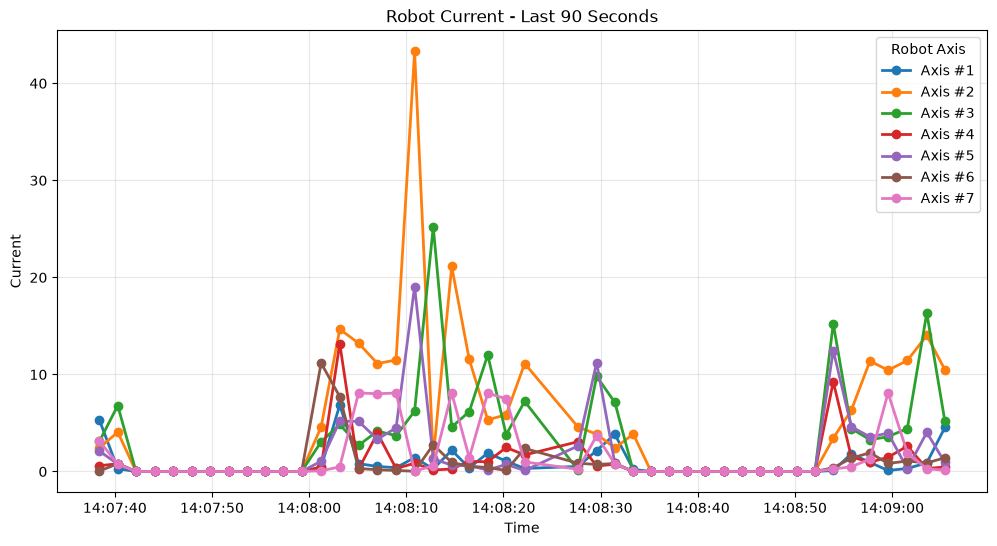

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import time
from IPython.display import clear_output

axes = [
    "axis_1",
    "axis_2",
    "axis_3",
    "axis_4",
    "axis_5",
    "axis_6",
    "axis_7"
]

colors = plt.cm.tab10.colors

while True:

    # Read records from database
    history_df = db.read_data()

    history_df["recorded_at"] = pd.to_datetime(
        history_df["recorded_at"],
        errors="coerce"
    )

    history_df = history_df.dropna(subset=["recorded_at"])

    history_df = history_df.sort_values("recorded_at")

    # Latest 45 records
    history_df = history_df.tail(45)

    clear_output(wait=True)

    fig, ax = plt.subplots(figsize=(12, 6))

    for i, axis in enumerate(axes):

        if axis in history_df.columns:

            axis_data = pd.to_numeric(
                history_df[axis],
                errors="coerce"
            )

            ax.plot(
                history_df["recorded_at"],
                axis_data,
                marker="o",
                linewidth=2,
                color=colors[i % len(colors)],
                label=f"Axis #{i + 1}"
            )

    ax.set_title("Robot Current - Last 90 Seconds")
    ax.set_xlabel("Time")
    ax.set_ylabel("Current")

    ax.xaxis.set_major_formatter(
        mdates.DateFormatter("%H:%M:%S")
    )

    ax.grid(True, alpha=0.3)
    ax.legend(title="Robot Axis")

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    print(f"Showing latest {len(history_df)} records")

    time.sleep(2)

## Normal Robot Behaviour

Historical robot current data from the database is used to determine normal robot behaviour.

Zero-current readings are ignored because they represent a stopped robot.

For each of the 7 robot axes, the mean, median, standard deviation, and normal operating ranges are calculated.

In [ ]:
import pandas as pd

# Robot axes in the database
axes = [
    "axis_1",
    "axis_2",
    "axis_3",
    "axis_4",
    "axis_5",
    "axis_6",
    "axis_7"
]

# Read historical data from Neon database
historical_df = db.read_data()

# Keep only Current records
historical_df = historical_df[
    historical_df["trait"].str.lower() == "current"
].copy()

# Convert axis values to numeric
for axis in axes:
    historical_df[axis] = pd.to_numeric(
        historical_df[axis],
        errors="coerce"
    )

# Ignore zero values
# Zero means the robot is stopped
active_current = historical_df[axes].where(
    historical_df[axes] > 0
)

# Calculate normal robot behaviour
normal_behavior = pd.DataFrame({
    "Active Records": active_current.count(),
    "Mean Current": active_current.mean(),
    "Median Current": active_current.median(),
    "Standard Deviation": active_current.std(),
    "Normal Minimum (P05)": active_current.quantile(0.05),
    "Normal Maximum (P95)": active_current.quantile(0.95),
    "Anomaly Level (P99)": active_current.quantile(0.99)
})

# Rename rows for display
normal_behavior.index = [
    "Axis #1",
    "Axis #2",
    "Axis #3",
    "Axis #4",
    "Axis #5",
    "Axis #6",
    "Axis #7"
]

# Round values
normal_behavior = normal_behavior.round(2)

display(normal_behavior)

c:\Users\admin\Desktop\Ai-Fall\CSCN8010-Foundation Machine Learning Framework\Week4\Lab1\Practical-Lab-1--Predictive-Maintenance-Linear-Regression-Based-Alerts\src\database_service\database_service_agent.py:58: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql_query(query, connection)


,Active Records,Mean Current,Median Current,Standard Deviation,Normal Minimum (P05),Normal Maximum (P95),Anomaly Level (P99)
Axis #1,2837,2.16,0.70,3.40,0.10,7.74,20.84
Axis #2,2847,10.31,10.65,7.67,0.69,24.46,37.74
Axis #3,2875,8.34,6.69,6.57,1.27,23.88,30.79
Axis #4,2833,1.77,1.01,2.13,0.08,5.42,10.88
Axis #5,2874,2.67,1.65,2.73,0.13,7.82,12.51
Axis #6,2832,1.73,0.80,2.66,0.05,6.63,13.78
Axis #7,2834,2.44,0.73,3.02,0.05,8.10,8.11
